In [1]:
# load cleaned data

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_real_estate_ads.csv")
df.head()

C:\Users\Amir\AppData\Local\Temp\ipykernel_19436\915465103.py:6: DtypeWarning: Columns (13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("cleaned_real_estate_ads.csv")


,cat3_slug,city_slug,neighborhood_slug,created_at_month,price_value,land_size,building_size,deed_type,floor,rooms_count,...,has_warehouse,has_parking,construction_year,has_water,has_electricity,has_gas,has_pool,has_jacuzzi,has_sauna,property_type
0,apartment-sell,tehran,gholhak,2405,8.500000e+09,NaN,60.0,NaN,3.0,1.0,...,True,True,1384.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,apartment-sell,mashhad,emamreza,2405,5.750000e+09,NaN,115.0,single_page,4.0,2.0,...,True,True,1403.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,apartment-sell,tehran,dardasht,2409,8.700000e+09,NaN,100.0,NaN,4.0,2.0,...,True,True,1393.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,apartment-sell,mahdasht-city,NaN,2406,6.500000e+08,NaN,78.0,single_page,4.0,2.0,...,True,True,1396.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,apartment-sell,mashhad,faramarzabbasi,2410,3.000000e+09,NaN,80.0,NaN,3.0,2.0,...,False,True,1387.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 1. Univariate (Target) Analysis

## 1.1 Price Value

In [2]:
df["price_value"].describe(percentiles=[.25, .5, .75, .9, .95, .99])

count    4.234250e+05
mean     1.552722e+10
std      5.292924e+11
min      1.000000e+00
25%      1.750000e+09
50%      3.150000e+09
75%      6.100000e+09
90%      1.200000e+10
95%      1.950000e+10
99%      5.950000e+10
max      1.000000e+14
Name: price_value, dtype: float64

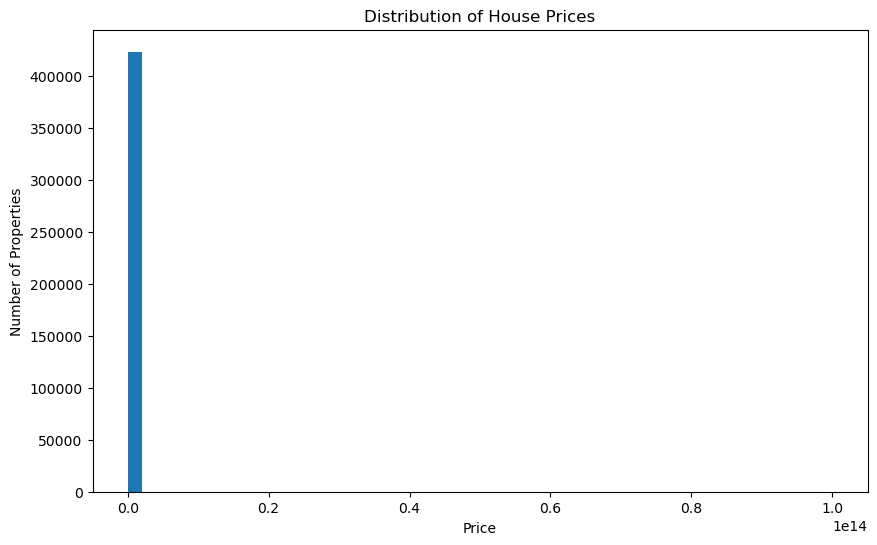

In [3]:
plt.figure(figsize=(10, 6))

plt.hist(df["price_value"], bins=50)

plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.title("Distribution of House Prices")

plt.show()

This histogram and the quantiles of price value reveals that almost all observations are compressed into the very left side of the histogram, while the x-axis extends to approximately 10^14.

So the price distribution is extremely right-skewed, and there are probably a few very large price values that are dominating the visualization.

Nonetheless we don't immediately delete those observations. Before doing that, we will investigate the high values and due to the features they have, will check their validation.

In [4]:
df[df["price_value"] > df["price_value"].quantile(0.98)]

,cat3_slug,city_slug,neighborhood_slug,created_at_month,price_value,land_size,building_size,deed_type,floor,rooms_count,...,has_warehouse,has_parking,construction_year,has_water,has_electricity,has_gas,has_pool,has_jacuzzi,has_sauna,property_type
8,apartment-sell,tehran,kamraniyeh,2411,1.330000e+11,NaN,400.0,NaN,5.0,4.0,...,True,True,1402.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,apartment-sell,kish,NaN,2412,6.500000e+10,NaN,200.0,NaN,30.0,3.0,...,False,True,1401.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
178,apartment-sell,tehran,amaniyeh,2411,3.700000e+10,NaN,150.0,single_page,2.0,3.0,...,True,True,1399.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,house-villa-sell,shiraz,farhangshahr,2411,4.700000e+10,400.0,250.0,NaN,NaN,3.0,...,True,True,1378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
319,house-villa-sell,izadshahr,NaN,2407,5.700000e+10,970.0,150.0,NaN,NaN,2.0,...,True,True,1369.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
423277,apartment-sell,tehran,aghdasieh,2411,5.700000e+10,NaN,217.0,NaN,1.0,3.0,...,True,True,1390.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
423305,apartment-sell,shiraz,eram-shiraz,2412,4.000000e+10,NaN,310.0,NaN,2.0,3.0,...,True,True,1402.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
423318,apartment-sell,tehran,farmaniyeh,2409,5.000000e+10,NaN,215.0,single_page,2.0,3.0,...,True,True,1396.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
423323,apartment-sell,tehran,farmaniyeh,2410,6.500000e+10,NaN,230.0,single_page,5.0,3.0,...,True,True,1399.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Most of the properties with high price are about the modern and expensive neighberhoods or incorrectly entered to the dataset. The very high prices of certain houses in upscale neighborhoods are due to wrong policies or incorrect pricing in Iran. For this reason, we treat them as outliers and remove them from the dataset. 

Furthermore there are some very low prices that are not legitimate. Thus we should get rid of these properties from dataset.

In [5]:
# remove the rows with price_value above 98% quantile because of unusually high prices
df = df[df["price_value"] < df["price_value"].quantile(0.98)]

In [6]:
# observe the different quantiles of low price value

for percent in range(1,10):
    print(f"Quantile {percent / 100} : {df[df['price_value'] < df['price_value'].quantile(percent / 100)]['price_value'].max()}") 

Quantile 0.01 : 11440.0
Quantile 0.02 : 2880000.0
Quantile 0.03 : 111111110.0
Quantile 0.04 : 448000000.0
Quantile 0.05 : 649000000.0
Quantile 0.06 : 768000000.0
Quantile 0.07 : 849000000.0
Quantile 0.08 : 928000000.0
Quantile 0.09 : 999999999.0


In [7]:
# remove the rows with price_value below 3% quantile because of unusually low prices

df = df[df["price_value"] > df["price_value"].quantile(0.03)]

In [8]:
df["price_value"].describe(percentiles=[.25, .5, .75, .9, .95])


count    4.017680e+05
mean     4.977446e+09
std      5.202752e+09
min      1.111111e+08
25%      1.800000e+09
50%      3.200000e+09
75%      6.000000e+09
90%      1.100000e+10
95%      1.550000e+10
max      3.596000e+10
Name: price_value, dtype: float64

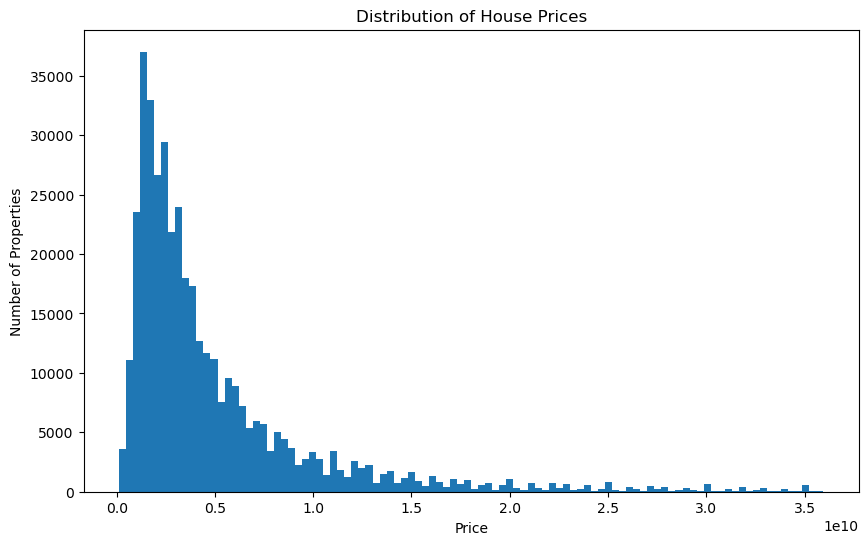

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(df["price_value"], bins=100)

plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.title("Distribution of House Prices")

plt.show()

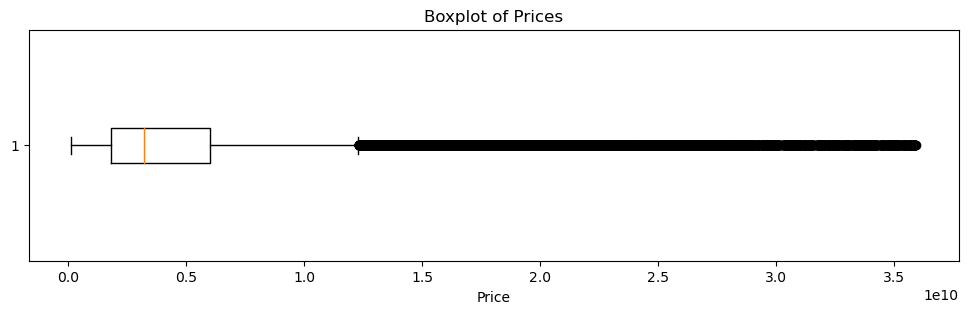

In [10]:
plt.figure(figsize=(12, 3))

plt.boxplot(df["price_value"], vert=False)

plt.xlabel("Price")
plt.title("Boxplot of Prices")

plt.show()

There are a very large number of points beyond the upper whisker; But this does not mean that all of those points should be removed.
In a real-estate dataset, this statistical definition can identify many perfectly legitimate expensive properties as outliers.

We will detect outliers in the multivariate analysis.

# 2. Multivariate Analysis

In [11]:
import seaborn as sns

Text(0.5, 1.0, 'Correlation Matrix of Real Estate Features')

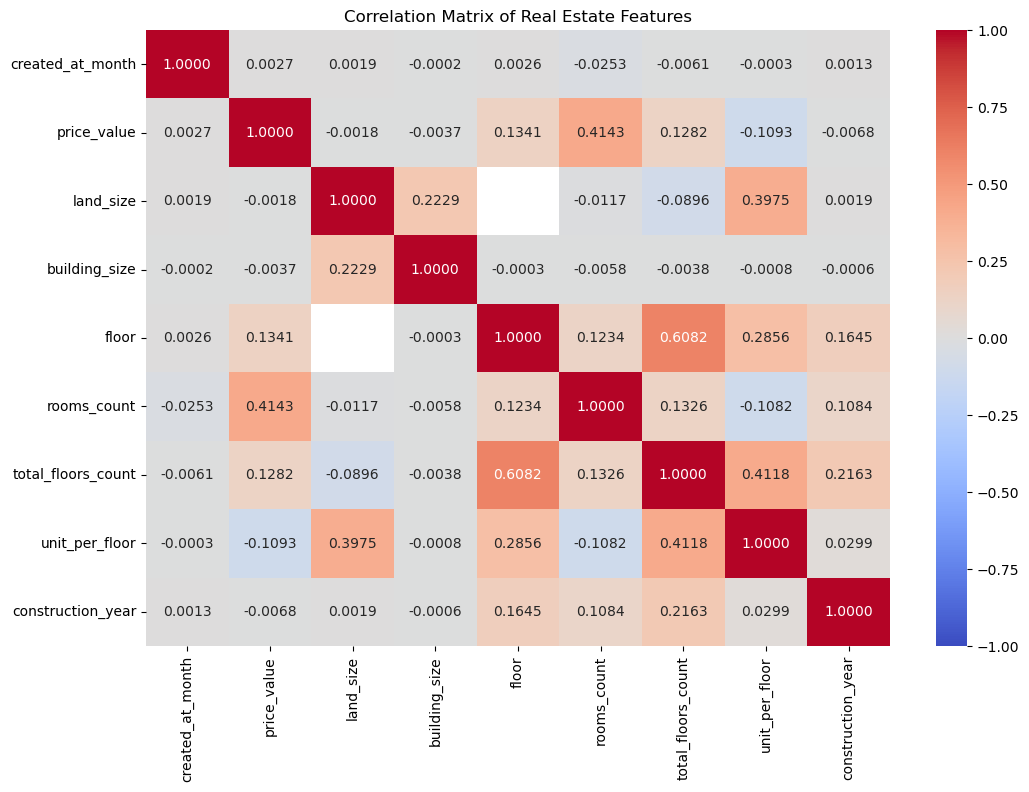

In [12]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".4f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix of Real Estate Features")

Generally correlation does't imply that a feature should automatically be included in the model. This matrix broadly doesn't demonestrate any strong relation between price and other features. So we need to do bivariate analysis and investigate relationships and discover outliers.

## 2.1 Price & Month of Ad Posting

created_at_month
2102    2.750000e+10
2106    1.200000e+09
2205    1.200000e+09
2206    9.000000e+09
2207    1.600000e+09
2208    6.700000e+09
2210    3.966667e+09
2211    2.070000e+09
2212    1.876667e+09
2301    3.925000e+09
2302    6.283333e+09
2303    1.950000e+09
2304    4.750000e+09
2305    6.629500e+09
2306    4.401481e+09
2307    5.690125e+09
2308    4.857565e+09
2309    4.421986e+09
2310    6.992955e+09
2311    4.323008e+09
2312    5.360704e+09
2401    5.192766e+09
2402    4.950641e+09
2403    4.990708e+09
2404    5.623442e+09
2405    5.129987e+09
2406    4.888477e+09
2407    4.872113e+09
2408    4.792348e+09
2409    4.874970e+09
2410    4.999002e+09
2411    5.033855e+09
2412    5.147440e+09
2501    5.441964e+09
2502    4.955602e+09
2503    6.110000e+09
Name: price_value, dtype: float64


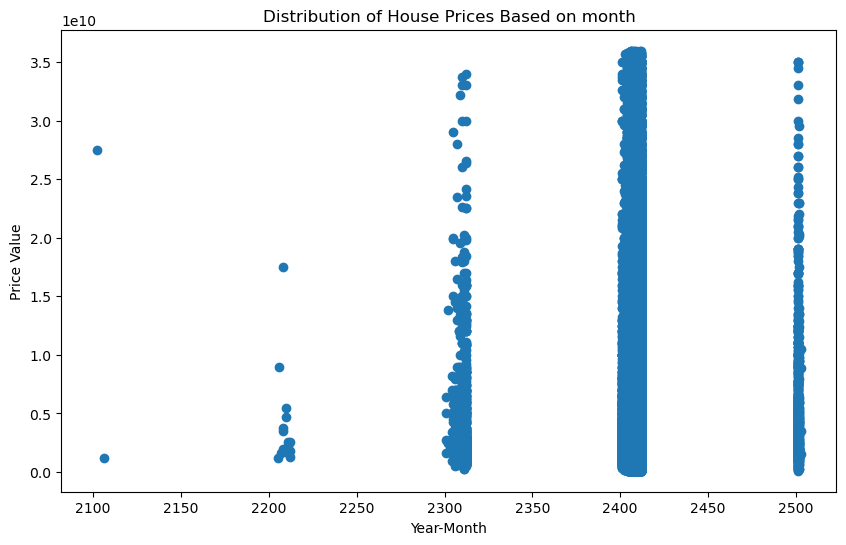

In [13]:
# investigate the price values group by each month

print(df.groupby("created_at_month")["price_value"].mean())

plt.figure(figsize=(10, 6))

plt.scatter(df["created_at_month"],y=df["price_value"])

plt.xlabel("Year-Month")
plt.ylabel("Price Value")
plt.title("Distribution of House Prices Based on month")

plt.show()

Based on scatter plot in above and mean of each month, it almost be concluded that the price values distrobuted normally based on monthly basis.

## 2.2 Price & Land and Building Size

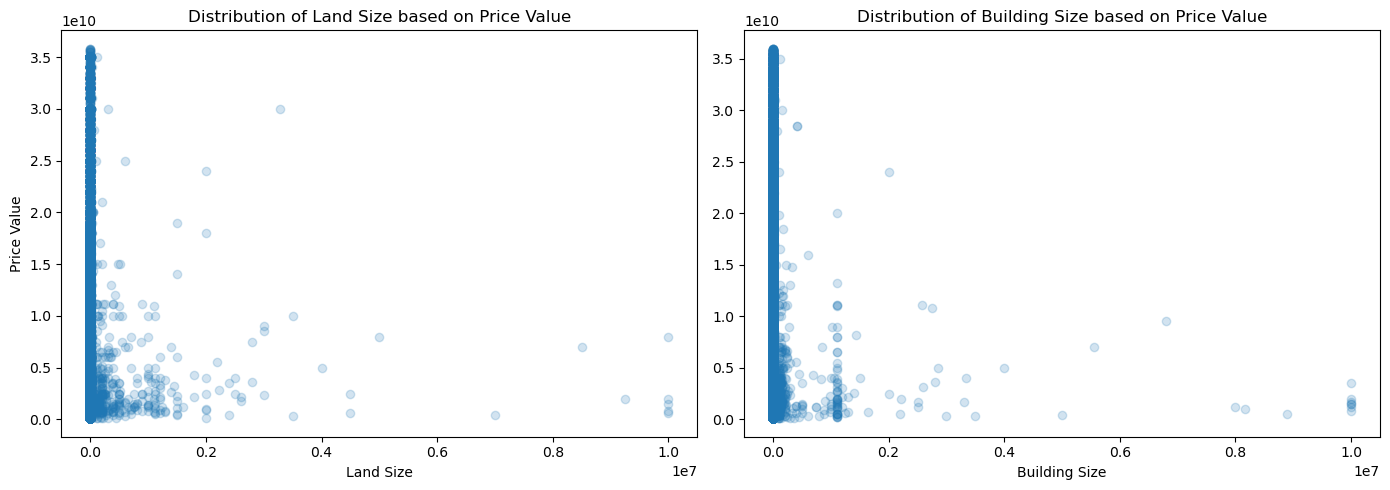

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Land size distribution
axes[0].scatter(df["land_size"],y=df["price_value"],alpha=0.2)
axes[0].set_xlabel("Land Size")
axes[0].set_ylabel("Price Value")
axes[0].set_title("Distribution of Land Size based on Price Value")

# Building size distribution
axes[1].scatter(df["building_size"],y= df["price_value"],alpha=0.2)
axes[1].set_xlabel("Building Size")
axes[1].set_title("Distribution of Building Size based on Price Value")

plt.tight_layout()
plt.show()

Both of them are significently right-skewed and it's clear that there are some anomaly in the dataset. We can detect outliers, but before remove them we should notice that the other features also impact the price value (Each feature has its own impact - to a greater or lesser extent.)

In [15]:
print("Land size discription:")
print(df["land_size"].describe(percentiles=[.25, .5, .75, .9, .95, .99]))
print("\n------------------------------------\n")
print("Building size discription:")
print(df["building_size"].describe(percentiles=[.25, .5, .75, .9, .95, .99]))

Land size discription:
count    1.114350e+05
mean     2.969494e+03
std      9.738083e+04
min      1.000000e+00
25%      1.300000e+02
50%      2.000000e+02
75%      3.000000e+02
90%      5.700000e+02
95%      1.000000e+03
99%      2.900000e+03
max      1.000000e+07
Name: land_size, dtype: float64

------------------------------------

Building size discription:
count    4.017560e+05
mean     8.201134e+02
std      5.537601e+04
min      1.000000e+00
25%      7.500000e+01
50%      9.800000e+01
75%      1.330000e+02
90%      1.860000e+02
95%      2.500000e+02
99%      5.000000e+02
max      1.000000e+07
Name: building_size, dtype: float64


In [16]:
df[df["land_size"].notnull()]["cat3_slug"].unique()

array(['house-villa-sell'], dtype=object)

The `land_size` feature is only possessed by the **house-villa**. It denotes to whole area land (contains garden, yard and ...). But some users consider it to be merely house yard or garden area or something else. Thus we can't reason anything about this feature; Instead we can conclude that the higher values of `land_size` relate to agricultural gardens that also include a small building or villa gardens. Therefore, since our project concerns housing prices, we are removing them.

In the other hand, the `building_size` value over than 1000 and less than 15 seems kind of unconventional (the smaller items seem like a garden with a small house). We consider them as outliers or error and remove them too.

In [17]:
print(df[(df["land_size"] > df["land_size"].quantile(0.97))].sort_values(by="price_value",ascending=False))

df = df[(df["land_size"] < df["land_size"].quantile(0.97)) | (df["land_size"].isnull())]

               cat3_slug             city_slug neighborhood_slug  \
215629  house-villa-sell                shiraz            gouyom   
212480  house-villa-sell               lahijan               NaN   
395876  house-villa-sell  abbasabad-mazandaran               NaN   
163512  house-villa-sell           pardis-city               NaN   
149427  house-villa-sell            kermanshah               NaN   
...                  ...                   ...               ...   
219896  house-villa-sell              borujerd               NaN   
213773  house-villa-sell               shahrud               NaN   
353471  house-villa-sell            shahrekord               NaN   
120612  house-villa-sell            torbat-jam               NaN   
62190   house-villa-sell                 karaj           azimieh   

        created_at_month   price_value  land_size  building_size    deed_type  \
215629              2411  3.500000e+10     4000.0         4000.0  single_page   
212480              2

In [18]:
print(df[df["building_size"] > 1000][["price_value","land_size","building_size"]].describe())
print(df[df["building_size"] < 15][["price_value","land_size","building_size"]].describe())

df = df[df["building_size"] < 1000]
df = df[df["building_size"] > 15]

        price_value    land_size  building_size
count  5.920000e+02   347.000000   5.920000e+02
mean   4.180749e+09   471.694524   3.042047e+05
std    5.600909e+09   389.656621   1.059830e+06
min    1.150000e+08     7.000000   1.002000e+03
25%    1.111111e+09   150.000000   1.366500e+03
50%    2.000000e+09   280.000000   6.250000e+04
75%    4.982500e+09   940.500000   1.250000e+05
max    3.500000e+10  1194.000000   1.000000e+07
        price_value    land_size  building_size
count  1.198000e+03  1117.000000    1198.000000
mean   2.689883e+09   551.779767       3.520868
std    3.843368e+09   296.268604       4.093006
min    1.200000e+08     1.000000       1.000000
25%    6.500000e+08   350.000000       1.000000
50%    1.400000e+09   500.000000       1.000000
75%    3.200000e+09   800.000000       6.000000
max    3.100000e+10  1183.000000      14.000000


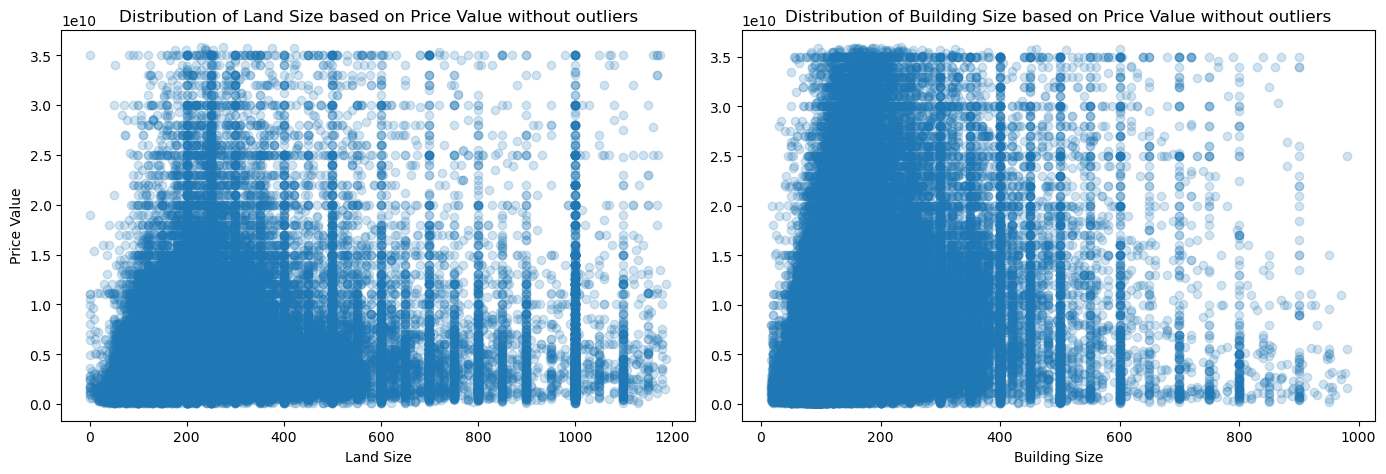

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Land size distribution
axes[0].scatter(df["land_size"],y=df["price_value"],alpha=0.2)
axes[0].set_xlabel("Land Size")
axes[0].set_ylabel("Price Value")
axes[0].set_title("Distribution of Land Size based on Price Value without outliers")

# Building size distribution
axes[1].scatter(df["building_size"],y= df["price_value"],alpha=0.2)
axes[1].set_xlabel("Building Size")
axes[1].set_title("Distribution of Building Size based on Price Value without outliers")

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Correlation Matrix of Real Estate Features')

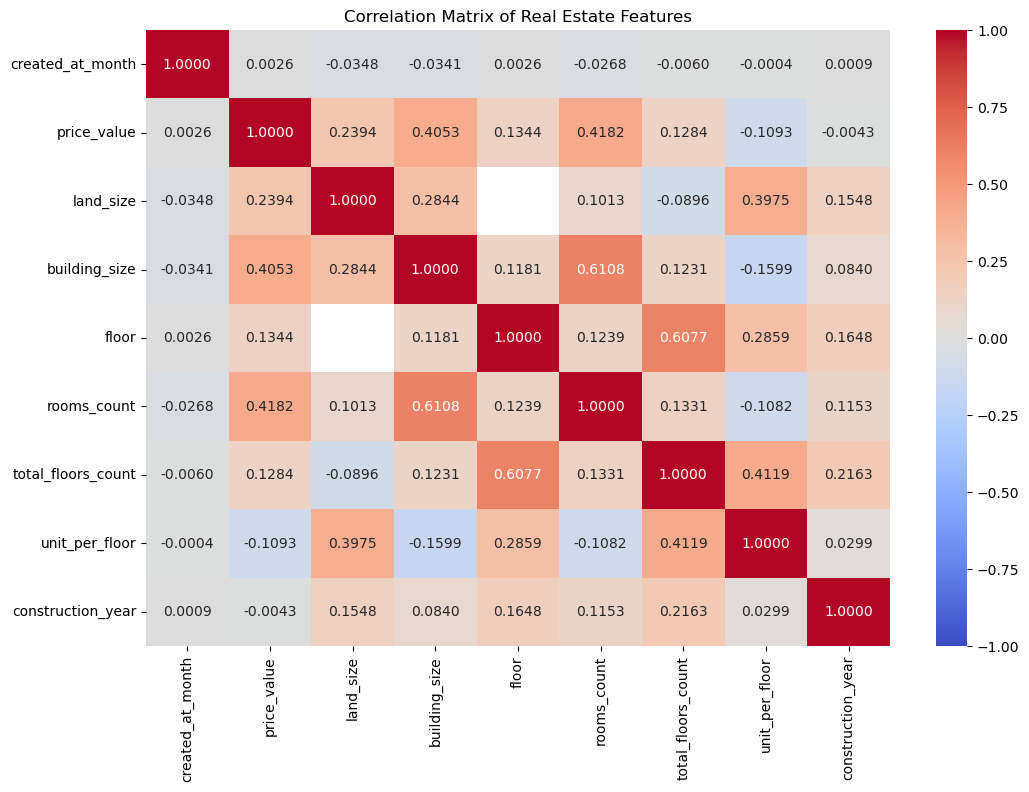

In [20]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".4f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix of Real Estate Features")

## 2.3 Price & Number of Rooms

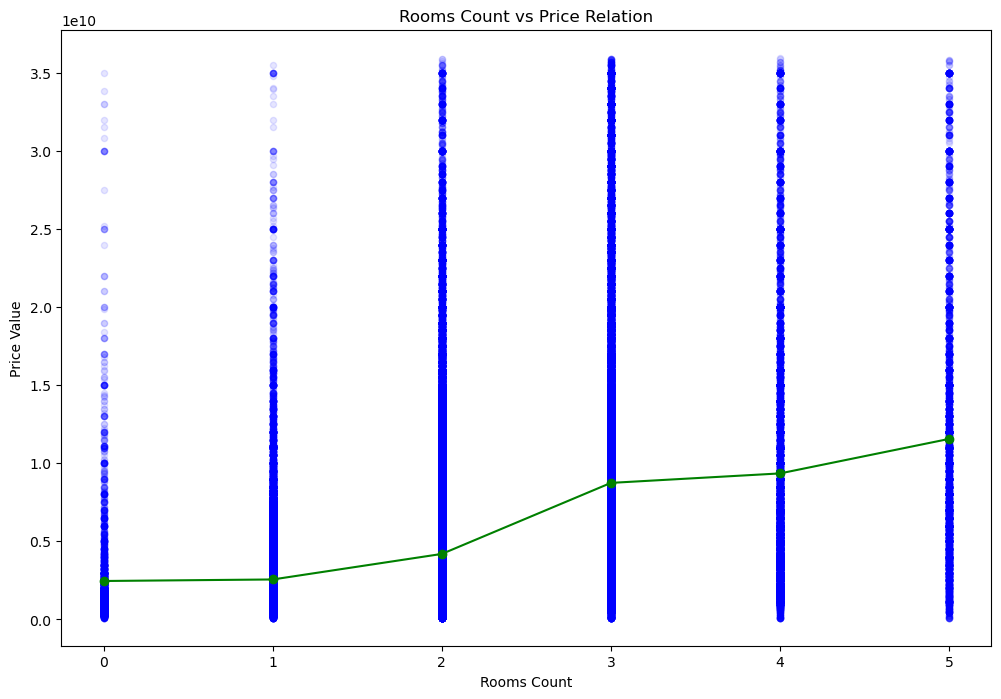

In [ ]:
plt.figure(figsize=(12, 8))

rooms_price = df.groupby("rooms_count")["price_value"].mean()

rooms_counts = rooms_price.index.to_numpy()
price_means = rooms_price.values

plt.plot(rooms_counts, price_means, color="green", marker="o")

fo = df.sort_values(by="rooms_count", ascending=True)
plt.scatter(fo["rooms_count"], fo["price_value"], color="blue", marker="o", s=20,alpha=0.1)

plt.title("Rooms Count vs Price Relation")
plt.xlabel("Rooms Count")
plt.ylabel("Average Price Value")

plt.show()

The rooms count has a small impact on the price value and increases the price.

## 2.4 Price & neighborhood or City 

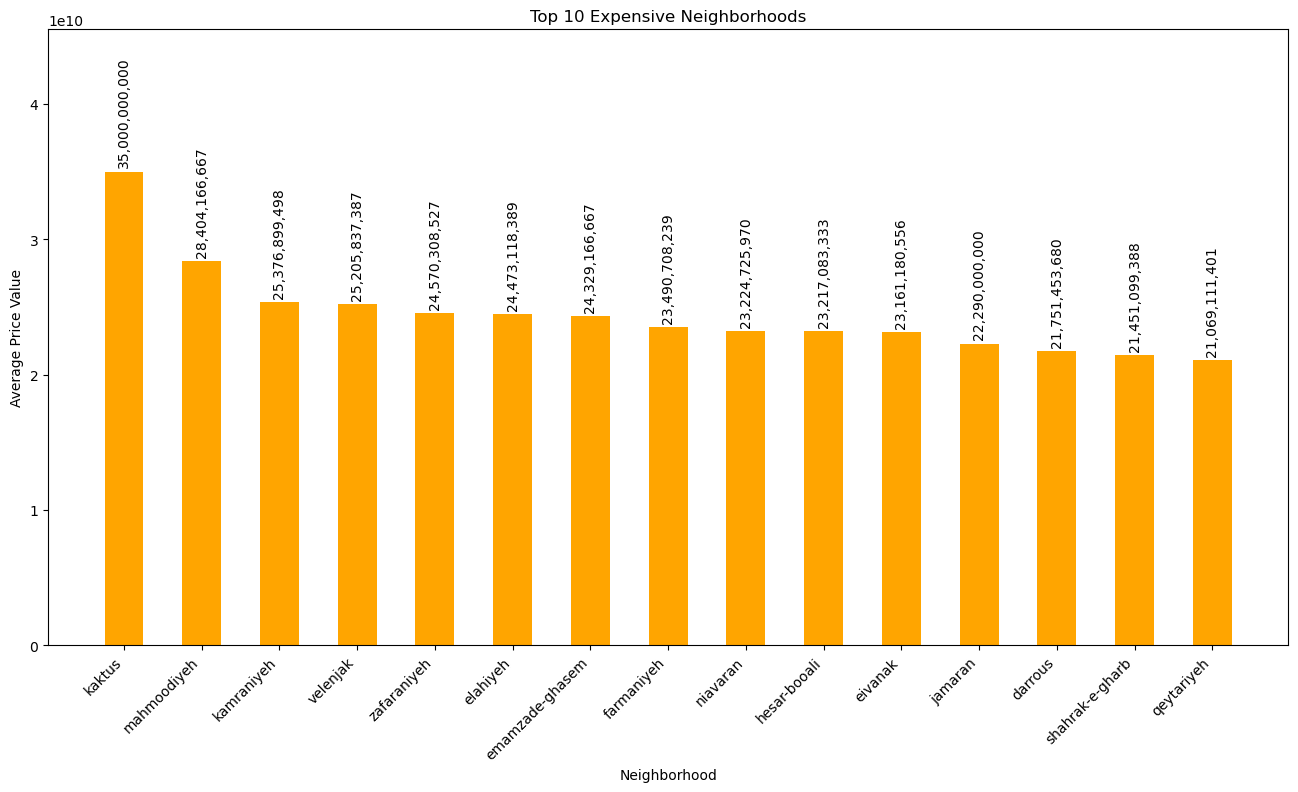

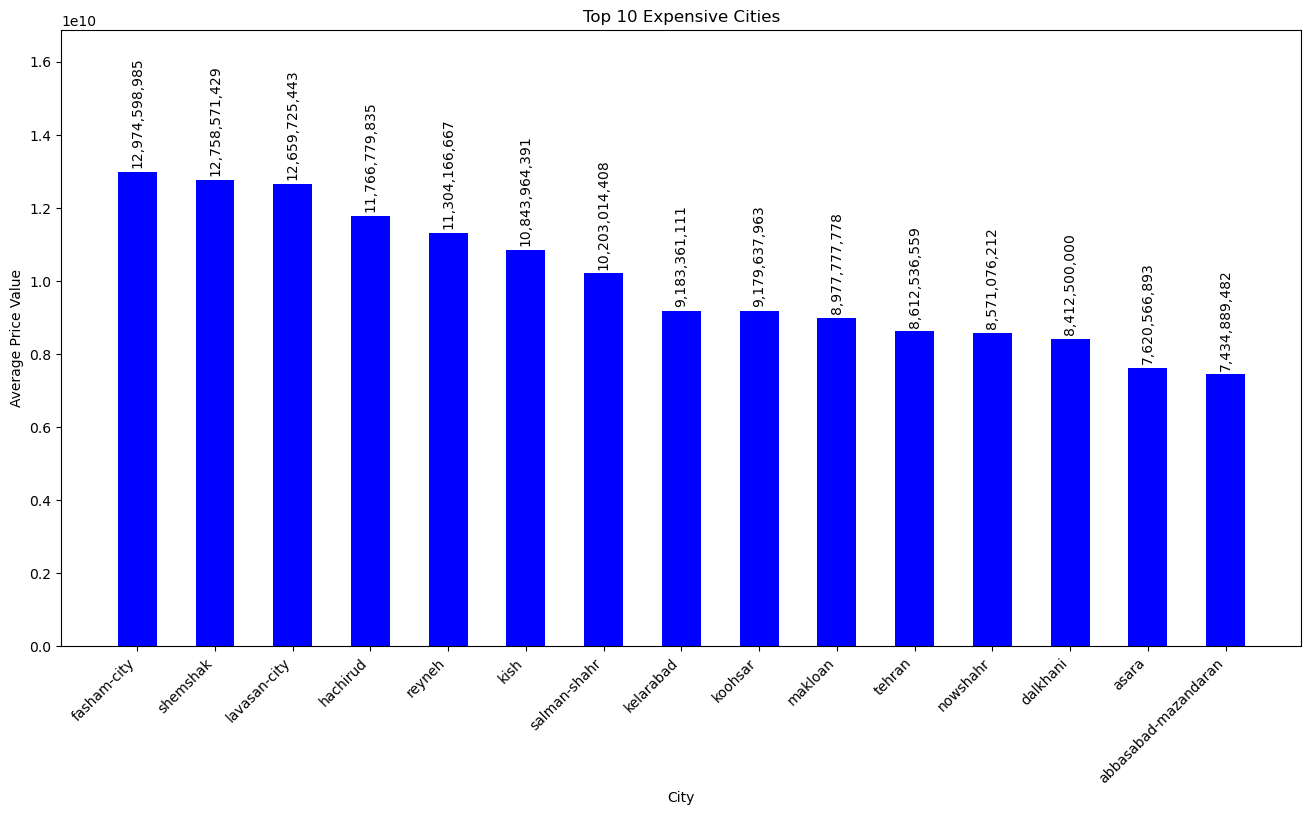

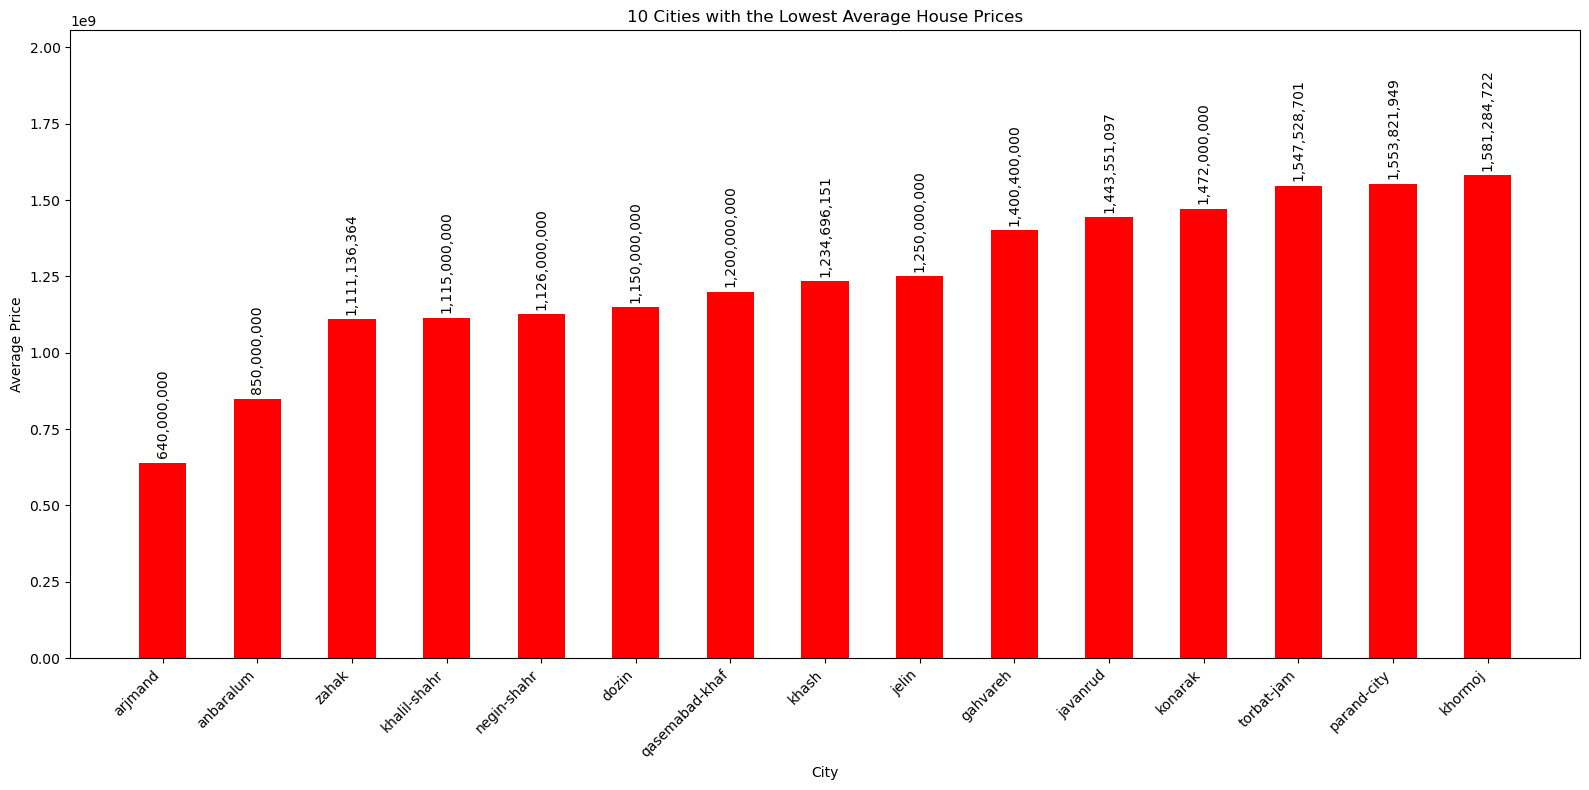

In [22]:
# neighborhood and price value

neighborhood_price = df.groupby(["neighborhood_slug"])["price_value"].mean()
top_neighborhood = neighborhood_price.sort_values(ascending=False).head(15).index.to_numpy()
neigh_price_means = neighborhood_price.sort_values(ascending=False).head(15).values

plt.figure(figsize=(16, 8))

top_neighborhood_bar = plt.bar(top_neighborhood, neigh_price_means, color="orange", width=0.5)

plt.title("Top 10 Expensive Neighborhoods")
plt.xlabel("Neighborhood")
plt.ylabel("Average Price Value")

plt.bar_label(
    top_neighborhood_bar,
    labels=[f"{price:,.0f}" for price in neigh_price_means],
    label_type="edge",
    padding=3,
    rotation=90
)

plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(neigh_price_means) * 1.30)

plt.show()

# city and price value
city_price = df.groupby(["city_slug"])["price_value"].mean()
top_cities = city_price.sort_values(ascending=False).head(15).index.to_numpy()
top_city_price_means = city_price.sort_values(ascending=False).head(15).values

plt.figure(figsize=(16, 8))

top_cities_bar = plt.bar(top_cities, top_city_price_means, color="blue", width=0.5)

plt.title("Top 10 Expensive Cities")
plt.xlabel("City")
plt.ylabel("Average Price Value")

plt.bar_label(
    top_cities_bar,
    labels=[f"{price:,.0f}" for price in top_city_price_means],
    label_type="edge",
    padding=3,
    rotation=90
)

plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(top_city_price_means) * 1.30)

plt.show()

lowest_cities = city_price.sort_values(ascending=True).head(15).index.to_numpy()
lowest_city_price_means = city_price.sort_values(ascending=True).head(15).values

plt.figure(figsize=(16, 8))

lowest_cities_bar = plt.bar(
    lowest_cities,
    lowest_city_price_means,
    color="red",
    width=0.5
)

plt.title("10 Cities with the Lowest Average House Prices")
plt.xlabel("City")
plt.ylabel("Average Price")

plt.bar_label(
    lowest_cities_bar,
    labels=[f"{price:,.0f}" for price in lowest_city_price_means],
    label_type="edge",
    padding=3,
    rotation=90
)

plt.xticks(rotation=45, ha="right")
plt.ylim(0, max(lowest_city_price_means) * 1.30)

plt.tight_layout()
plt.show()


## 2.5 Price & Unit per Floor

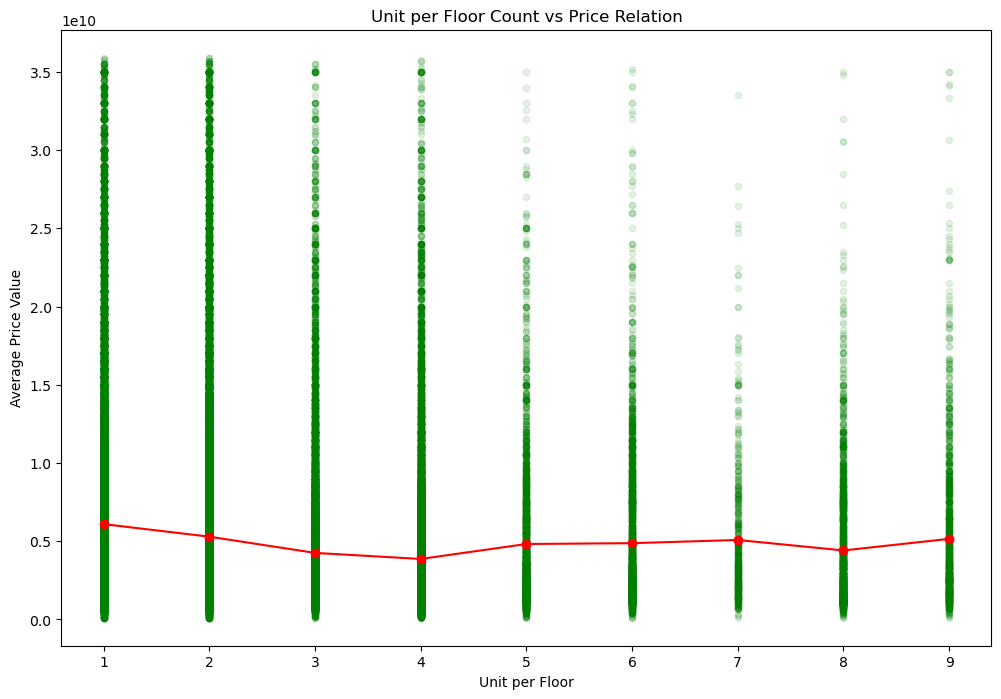

In [23]:
plt.figure(figsize=(12, 8))

unit_per_floor_price = df.groupby("unit_per_floor")["price_value"].mean()


units_counts = unit_per_floor_price.index.to_numpy()
unit_price_means = unit_per_floor_price.values

plt.plot(units_counts, unit_price_means, color="red", marker="o")

fo = df.sort_values(by="unit_per_floor", ascending=True)
plt.scatter(fo["unit_per_floor"], fo["price_value"], color="green", marker="o", s=20,alpha=0.1)

plt.title("Unit per Floor Count vs Price Relation")
plt.xlabel("Unit per Floor")
plt.ylabel("Average Price Value")

plt.show()

Having more units on each floor causes congestion and a lot of noise in the building. Because of that in the apartment with the more unit in floor may be decreased in the pricing  